# Analisis Sinyal Petir Karawang (Kelompok 5)

## 1. Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.ensemble import IsolationForest

df = pd.read_csv("data_dummy_sinyal_karawang_1000.csv", parse_dates=["waktu_utc"])
df.head()

,id_kejadian,waktu_utc,frekuensi_hz,metrik_sinyal,durasi_ms,versi_detektor,tingkat_keyakinan,id_stasiun,referensi_cuaca
0,EVT-000001,2026-10-01 00:24:06+00:00,1747.58,16.2,76,v2.3.1,0.99,STN-KRT,BMKG-KRW-20261001
1,EVT-000002,2026-10-01 00:55:42+00:00,2209.98,11.9,144,v2.2.9,0.77,STN-KRT,BMKG-KRW-20261001
2,EVT-000003,2026-10-01 01:01:55+00:00,1750.61,10.8,114,v2.3.0,0.79,STN-KLR,BMKG-KRW-20261001
3,EVT-000004,2026-10-01 01:16:15+00:00,2210.06,14.4,260,v2.3.0,0.86,STN-KRT,BMKG-KRW-20261001
4,EVT-000005,2026-10-01 01:47:26+00:00,1917.44,12.9,169,v2.3.1,0.91,STN-KRB,BMKG-KRW-20261001


## 2. Cek tipe data

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   id_kejadian        1000 non-null   str                
 1   waktu_utc          1000 non-null   datetime64[us, UTC]
 2   frekuensi_hz       1000 non-null   float64            
 3   metrik_sinyal      1000 non-null   float64            
 4   durasi_ms          1000 non-null   int64              
 5   versi_detektor     1000 non-null   str                
 6   tingkat_keyakinan  1000 non-null   float64            
 7   id_stasiun         1000 non-null   str                
 8   referensi_cuaca    1000 non-null   str                
dtypes: datetime64[us, UTC](1), float64(3), int64(1), str(4)
memory usage: 70.4 KB


## 3. Statistik dasar

### Jumlah kejadian per stasiun

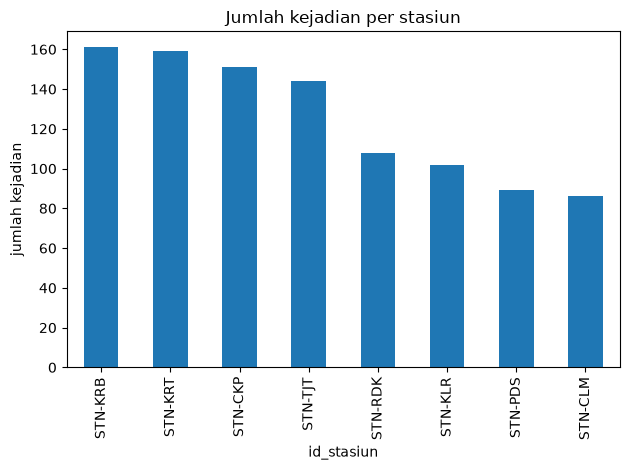

In [3]:
df["id_stasiun"].value_counts().plot(kind="bar", title="Jumlah kejadian per stasiun")
plt.ylabel("jumlah kejadian")
plt.tight_layout()
plt.show()

### Event rate harian

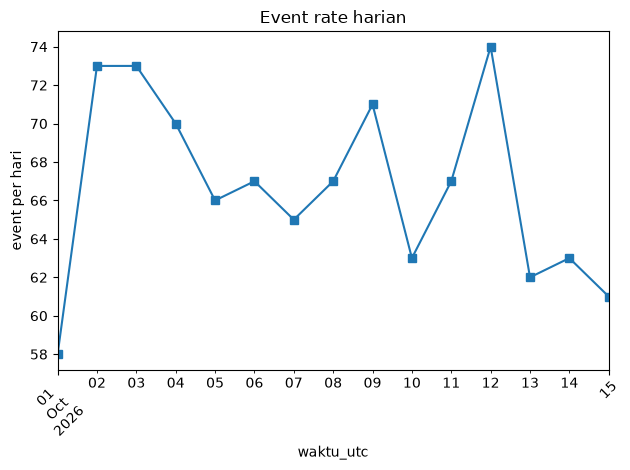

In [4]:
rate_harian = df.set_index("waktu_utc").resample("D").size()

rate_harian.plot(marker="s", title="Event rate harian")
plt.ylabel("event per hari")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Event rate rata-rata

In [5]:
durasi = df["waktu_utc"].max() - df["waktu_utc"].min()
durasi_jam = durasi.total_seconds() / 3600
durasi_hari = durasi_jam / 24

total_event = len(df)
rate_per_jam = total_event / durasi_jam
rate_per_hari = total_event / durasi_hari

print(f"Total event       : {total_event}")
print(f"Durasi pengamatan : {durasi_hari:.2f} hari ({durasi_jam:.1f} jam)")
print(f"Event rate        : {rate_per_jam:.2f} event/jam")
print(f"Event rate        : {rate_per_hari:.1f} event/hari")

Total event       : 1000
Durasi pengamatan : 14.94 hari (358.6 jam)
Event rate        : 2.79 event/jam
Event rate        : 66.9 event/hari


## 4. Baseline: outlier per event (metode IQR)

In [6]:
def cari_outlier_iqr(seri):
    q1, q3 = seri.quantile(0.25), seri.quantile(0.75)
    iqr = q3 - q1
    return (seri < q1 - 1.5 * iqr) | (seri > q3 + 1.5 * iqr)

for kolom in ["metrik_sinyal", "durasi_ms", "tingkat_keyakinan"]:
    df[f"outlier_{kolom}"] = cari_outlier_iqr(df[kolom])
    print(kolom, "->", df[f"outlier_{kolom}"].sum(), "outlier")

metrik_sinyal -> 3 outlier
durasi_ms -> 53 outlier
tingkat_keyakinan -> 0 outlier


## 5. Agregasi per jam

In [7]:
per_jam = (
    df.set_index("waktu_utc")
      .resample("1h")
      .agg(
          sambaran=("id_kejadian", "count"),
          metrik_rata=("metrik_sinyal", "mean"),
          durasi_rata=("durasi_ms", "mean"),
          yakin_rata=("tingkat_keyakinan", "mean"),
      )
)
per_jam = per_jam.fillna(per_jam.mean())  # jam kosong diisi rata-rata
per_jam.head()

,sambaran,metrik_rata,durasi_rata,yakin_rata
waktu_utc,,,,
2026-10-01 00:00:00+00:00,2,14.05,110.0,0.880000
2026-10-01 01:00:00+00:00,3,12.70,181.0,0.853333
2026-10-01 02:00:00+00:00,2,6.05,114.0,0.620000
2026-10-01 03:00:00+00:00,4,9.55,274.0,0.720000
2026-10-01 04:00:00+00:00,2,11.05,387.5,0.740000


## 6. Model: IsolationForest

In [8]:
fitur = ["sambaran", "metrik_rata", "durasi_rata", "yakin_rata"]
model = IsolationForest(contamination=0.03, random_state=42)
per_jam["anomali_if"] = model.fit_predict(per_jam[fitur]) == -1

print("Jam anomali:", per_jam["anomali_if"].sum(), "dari", len(per_jam))

Jam anomali: 11 dari 360


## 7. Hasil anomali (waktu WIB)

In [9]:
# versi WIB dari per_jam (aman walau data awalnya belum punya timezone)
p = per_jam.copy()
idx = p.index
if idx.tz is None:
    idx = idx.tz_localize("UTC")
p.index = idx.tz_convert("Asia/Jakarta")

p[p["anomali_if"]][fitur].round(2)

,sambaran,metrik_rata,durasi_rata,yakin_rata
waktu_utc,,,,
2026-10-02 17:00:00+07:00,2,6.20,844.00,0.59
2026-10-03 20:00:00+07:00,6,9.30,154.33,0.72
2026-10-08 02:00:00+07:00,2,13.50,877.50,0.93
2026-10-10 01:00:00+07:00,2,2.65,242.50,0.39
2026-10-11 02:00:00+07:00,3,15.20,275.00,0.96
2026-10-12 04:00:00+07:00,3,7.67,1059.67,0.66
2026-10-13 13:00:00+07:00,2,16.10,1044.00,0.92
2026-10-13 22:00:00+07:00,5,6.60,481.60,0.60
2026-10-14 05:00:00+07:00,2,3.40,414.50,0.46


### Bandingkan jam anomali dengan rata-rata

In [10]:
print("Rata-rata semua jam:")
print(per_jam[fitur].mean().round(2))

print("\nJam yang ketandain anomali:")
print(per_jam[per_jam["anomali_if"]][fitur].round(2))

Rata-rata semua jam:
sambaran         2.78
metrik_rata      9.98
durasi_rata    297.32
yakin_rata       0.74
dtype: float64

Jam yang ketandain anomali:
                           sambaran  metrik_rata  durasi_rata  yakin_rata
waktu_utc                                                                
2026-10-02 10:00:00+00:00         2         6.20       844.00        0.59
2026-10-03 13:00:00+00:00         6         9.30       154.33        0.72
2026-10-07 19:00:00+00:00         2        13.50       877.50        0.93
2026-10-09 18:00:00+00:00         2         2.65       242.50        0.39
2026-10-10 19:00:00+00:00         3        15.20       275.00        0.96
2026-10-11 21:00:00+00:00         3         7.67      1059.67        0.66
2026-10-13 06:00:00+00:00         2        16.10      1044.00        0.92
2026-10-13 15:00:00+00:00         5         6.60       481.60        0.60
2026-10-13 22:00:00+00:00         2         3.40       414.50        0.46
2026-10-14 19:00:00+00:00        

### Visualisasi (titik merah = anomali, label = tanggal & jam WIB)

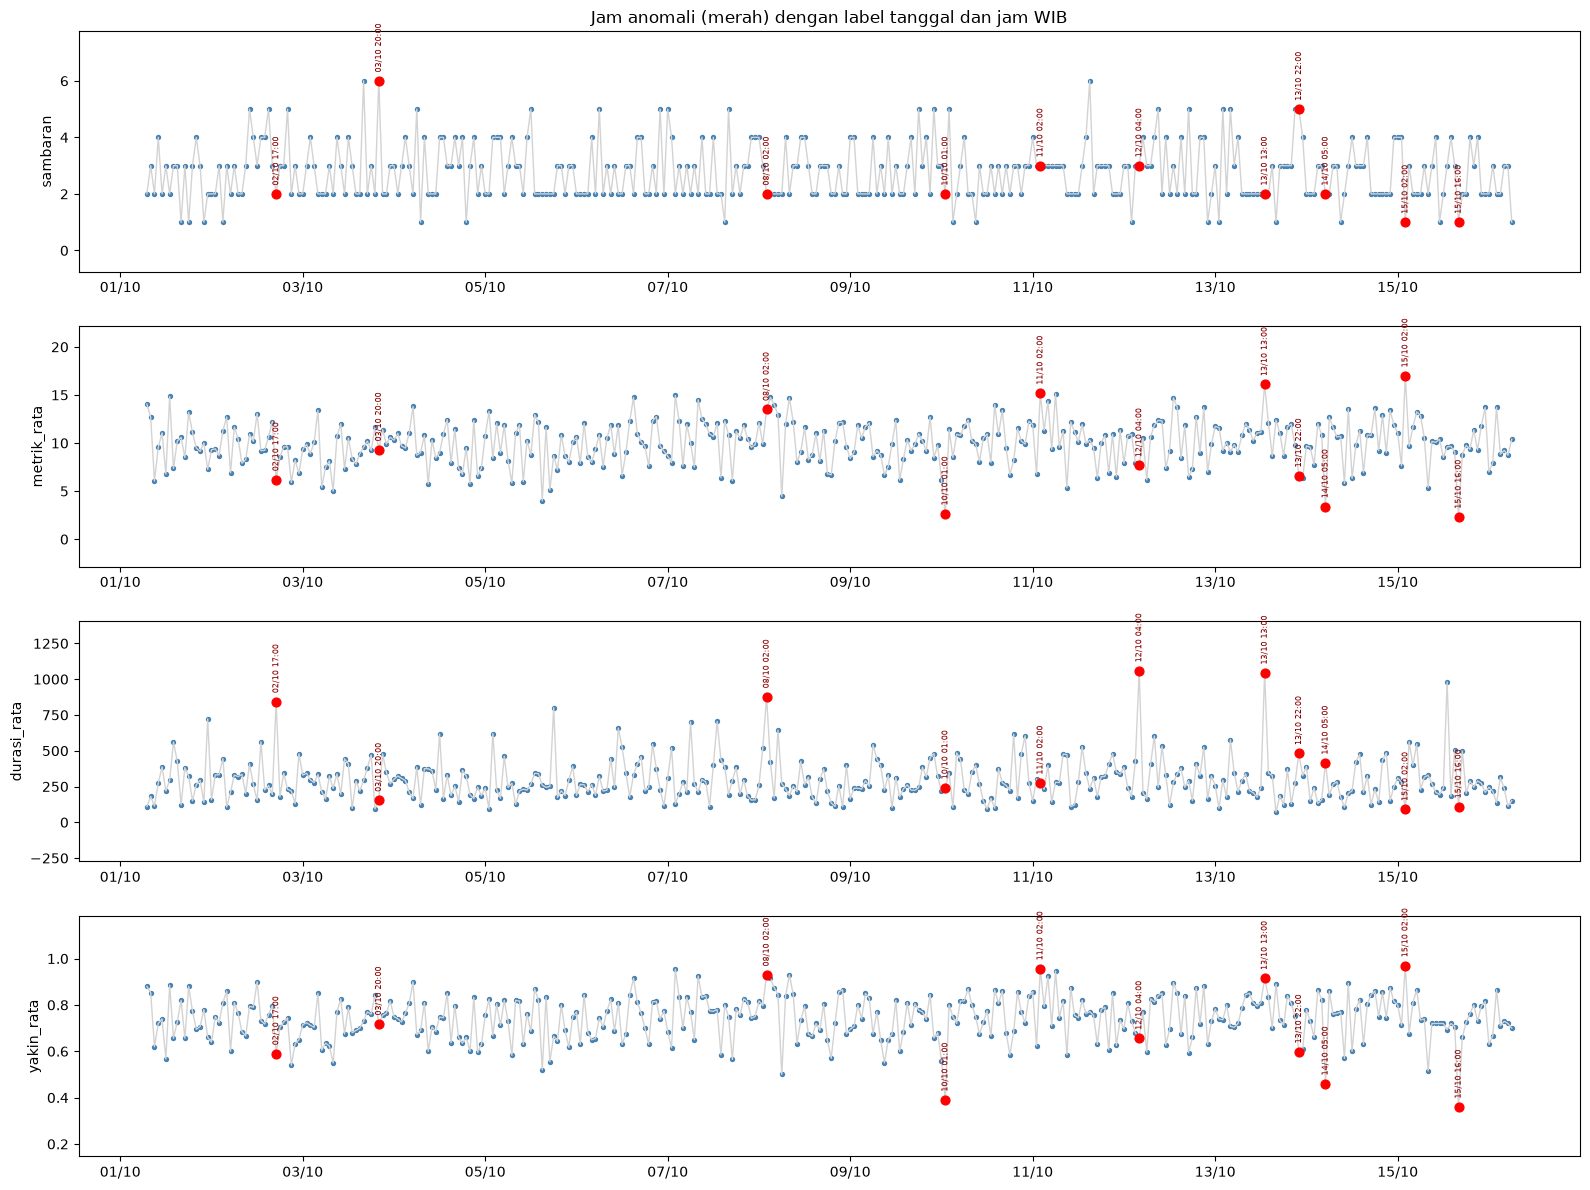

In [11]:
fig, axes = plt.subplots(len(fitur), 1, figsize=(16, 12), sharex=True)

for ax, kolom in zip(axes, fitur):
    normal = p[~p["anomali_if"]]
    anomali = p[p["anomali_if"]]

    ax.plot(p.index, p[kolom], color="lightgray", lw=1)
    ax.scatter(normal.index, normal[kolom], s=8, color="steelblue")
    ax.scatter(anomali.index, anomali[kolom], s=40, color="red", zorder=3)

    for waktu, baris in anomali.iterrows():
        ax.annotate(
            waktu.strftime("%d/%m %H:%M"),
            (waktu, baris[kolom]),
            textcoords="offset points", xytext=(0, 6),
            ha="center", va="bottom",
            fontsize=6, rotation=90, color="darkred",
        )

    ax.margins(y=0.35)
    ax.set_ylabel(kolom)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m", tz=p.index.tz))
    ax.tick_params(labelbottom=True)

axes[0].set_title("Jam anomali (merah) dengan label tanggal dan jam WIB")
plt.tight_layout()
plt.show()